<a href="https://colab.research.google.com/github/Maohtec/Entrega-Final-Analisis-Estadistico/blob/main/Etapa2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cargar la extensión rpy2 para permitir la ejecución de R dentro del Entorno de Python
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [ ]:
## Análisis Estadístico de Lectura - MOLEC 2023 y 2024

#Este documento contiene el flujo completo de análisis de los datos de MOLEC para los años 2023 y 2024 reorganizado y simplificado.

In [ ]:
 %load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


### Sección 1: Cargar todo y armar las variables

Acá preparamos el programa cargando los paquetes que nos sirven para los datos y las gráficas. También subimos las bases de datos de 2023 y 2024, armamos los grupos por edades (18-24 y 25-34 años) y creamos la variable de los formatos de libros (si leen en papel, digital o los dos).

In [ ]:
%%R
# Carga de librerías y datos iniciales
library(dplyr)
library(ggplot2)
library(e1071)

# cargamos las bases limpias
M23limpia = read.csv("DatosEquipo_2023_LISTO_ANALISIS.csv")
M24limpia = read.csv("DatosEquipo_2024_LISTO_ANALISIS.csv")

# creamos los grupos de edad
M23limpia$grupo_edad = ifelse(M23limpia$edad <= 24, "18-24", "25-34")
M24limpia$grupo_edad = ifelse(M24limpia$edad <= 24, "18-24", "25-34")

# agregamos el año a cada base
M23limpia$anio = "2023"
M24limpia$anio = "2024"

# creamos la variable formato de libro para 2023
M23limpia$formato_libro = NA
M23limpia$formato_libro[M23limpia$p8_1 == 1 & M23limpia$p8_2 == 2] = "Solo digital"
M23limpia$formato_libro[M23limpia$p8_1 == 2 & M23limpia$p8_2 == 1] = "Solo impreso"
M23limpia$formato_libro[M23limpia$p8_1 == 1 & M23limpia$p8_2 == 1] = "Ambos"

# creamos la variable formato de libro para 2024
M24limpia$formato_libro = NA
M24limpia$formato_libro[M24limpia$p8_1 == 1 & M24limpia$p8_2 == 2] = "Solo digital"
M24limpia$formato_libro[M24limpia$p8_1 == 2 & M24limpia$p8_2 == 1] = "Solo impreso"
M24limpia$formato_libro[M24limpia$p8_1 == 1 & M24limpia$p8_2 == 1] = "Ambos"

# unimos las bases para los análisis conjuntos
Mtotal = bind_rows(M23limpia, M24limpia)

### Sección 2: Anexo A - Ver si faltan datos

Antes de empezar, revisamos rápido si hay preguntas sin responder (datos vacíos o NAs) en los dos años para asegurarnos de que todo esté en orden.

In [ ]:
%%R
# ANEXO A - REVISION DE FALTANTES

variables = c("edad","nivel","p3_1","p3_5","p4",
              "p7","p8_1","p8_2","p26")

faltantes_2023 = sapply(M23limpia[variables], function(x) sum(is.na(x)))
porcentaje_2023 = sapply(M23limpia[variables], function(x) mean(is.na(x)) * 100)
validos_2023 = sapply(M23limpia[variables], function(x) sum(!is.na(x)))

faltantes_2024 = sapply(M24limpia[variables], function(x) sum(is.na(x)))
porcentaje_2024 = sapply(M24limpia[variables], function(x) mean(is.na(x)) * 100)
validos_2024 = sapply(M24limpia[variables], function(x) sum(!is.na(x)))

AnexoA = data.frame(
  Variable = variables,
  Validos_2023 = validos_2023,
  Faltantes_2023 = faltantes_2023,
  Porcentaje_2023 = round(porcentaje_2023, 2),
  Validos_2024 = validos_2024,
  Faltantes_2024 = faltantes_2024,
  Porcentaje_2024 = round(porcentaje_2024, 2)
)

print(AnexoA)
write.csv(AnexoA, "AnexoA_Faltantes_MOLEC_2023_2024.csv", row.names = FALSE)

              Variable         Categoria X2023 X2024
1          Leyo libros                Si 49.48 51.99
2         Lee internet                Si 56.75 52.17
3    Formato del libro      Solo impreso 66.43 66.33
4    Formato del libro      Solo digital 24.83 26.33
5    Formato del libro             Ambos  8.74  7.33
6            Obtencion Descarga gratuita 24.13 29.00
7            Obtencion Regalo o prestamo 34.62 36.33
8            Obtencion            Compra 41.26 34.67
9 Nivel de instruccion Categoria mediana  4.00  4.00


### Sección 3: Tabla 2 - Los números básicos

Acá calculamos los datos básicos de siempre: el promedio de libros leídos, el tiempo que tardan, los valores del medio (medianas) y qué tan variados son los resultados.

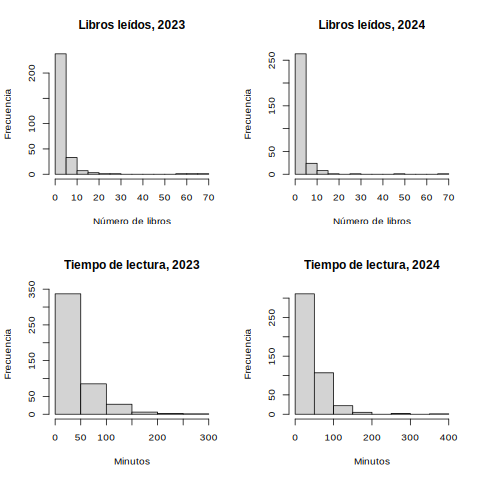

In [ ]:
%%R
# TABLA 2 - MEDIDAS DESCRIPTIVAS

medidas = function(x){
  x = x[!is.na(x)]
  n = length(x)
  media = mean(x)
  mediana = median(x)
  rango_medio = (min(x) + max(x)) / 2
  desviacion = sd(x)
  coef_variacion = (desviacion / media) * 100
  Q1 = quantile(x, 0.25)
  Q3 = quantile(x, 0.75)
  RIC = IQR(x)
  sesgo = skewness(x)
  curtosis = kurtosis(x)

  return(c(
    n = n,
    Media = media,
    Mediana = mediana,
    Rango_medio = rango_medio,
    Desviacion_estandar = desviacion,
    Coef_variacion = coef_variacion,
    Q1 = Q1,
    Q3 = Q3,
    RIC = RIC,
    Sesgo = sesgo,
    Curtosis = curtosis
  ))
}

p4_23 = medidas(M23limpia$p4)
p4_24 = medidas(M24limpia$p4)
p26_23 = medidas(M23limpia$p26)
p26_24 = medidas(M24limpia$p26)

Tabla2 = data.frame(
  Medida = c(
    "n", "Media", "Mediana", "Rango medio", "Desviacion estandar",
    "Coeficiente de variacion (%)", "Q1", "Q3", "Rango intercuartilico",
    "Sesgo", "Curtosis"
  ),
  p4_2023 = round(p4_23, 2),
  p4_2024 = round(p4_24, 2),
  p26_2023 = round(p26_23, 2),
  p26_2024 = round(p26_24, 2)
)

print(Tabla2)
write.csv(Tabla2, "Tabla2_Medidas_Descriptivas.csv", row.names = FALSE)

### Sección 4: Tabla 3 - Porcentajes generales

Sacamos los porcentajes sencillos de la gente para ver cuántos leen libros, cuántos usan internet, qué formatos prefieren y cómo consiguen lo que leen.

In [ ]:
%%R
# TABLA 3 - PORCENTAJES DE VARIABLES CATEGORICAS

p31_23 = prop.table(table(M23limpia$p3_1)) * 100
p31_24 = prop.table(table(M24limpia$p3_1)) * 100
libros_si_2023 = p31_23["1"]
libros_si_2024 = p31_24["1"]

p35_23 = prop.table(table(M23limpia$p3_5)) * 100
p35_24 = prop.table(table(M24limpia$p3_5)) * 100
internet_si_2023 = p35_23["1"]
internet_si_2024 = p35_24["1"]

p7_23 = prop.table(table(M23limpia$p7)) * 100
p7_24 = prop.table(table(M24limpia$p7)) * 100

formato_23 = prop.table(table(M23limpia$formato_libro)) * 100
formato_24 = prop.table(table(M24limpia$formato_libro)) * 100

nivel_mediana_2023 = median(M23limpia$nivel, na.rm = TRUE)
nivel_mediana_2024 = median(M24limpia$nivel, na.rm = TRUE)

Tabla3 = data.frame(
  Variable = c(
    "Leyo libros", "Lee internet", "Formato del libro",
    "Formato del libro", "Formato del libro", "Obtencion",
    "Obtencion", "Obtencion", "Nivel de instruccion"
  ),
  Categoria = c(
    "Si", "Si", "Solo impreso", "Solo digital", "Ambos",
    "Descarga gratuita", "Regalo o prestamo", "Compra", "Categoria mediana"
  ),
  `2023` = c(
    libros_si_2023, internet_si_2023, formato_23["Solo impreso"],
    formato_23["Solo digital"], formato_23["Ambos"], p7_23["1"],
    p7_23["2"], p7_23["3"], nivel_mediana_2023
  ),
  `2024` = c(
    libros_si_2024, internet_si_2024, formato_24["Solo impreso"],
    formato_24["Solo digital"], formato_24["Ambos"], p7_24["1"],
    p7_24["2"], p7_24["3"], nivel_mediana_2024
  )
)

Tabla3$X2023 = round(Tabla3$X2023, 2)
Tabla3$X2024 = round(Tabla3$X2024, 2)

print(Tabla3)
write.csv(Tabla3, "Tabla3_Variables_Categoricas.csv", row.names = FALSE)

# A tibble: 4 × 4
# Groups:   grupo_edad [2]
  grupo_edad  p3_5     n Porcentaje
  <chr>      <int> <int>      <dbl>
1 18-24          1   123       62.8
2 18-24          2    73       37.2
3 25-34          1   205       53.7
4 25-34          2   177       46.3
# A tibble: 4 × 4
# Groups:   grupo_edad [2]
  grupo_edad  p3_5     n Porcentaje
  <chr>      <int> <int>      <dbl>
1 18-24          1   111       57.2
2 18-24          2    83       42.8
3 25-34          1   190       49.6
4 25-34          2   193       50.4



Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



### Sección 5: Gráficas de distribución

Hacemos unos dibujos sencillos (histogramas) para ver de un vistazo si la gente lee mucho, poquito o nada, y cuánto tiempo se tardan.

In [ ]:
%%R
# HISTOGRAMAS DE DISTRIBUCION

par(mfrow = c(2,2))
hist(M23limpia$p4, main = "Libros leídos, 2023", xlab = "Número de libros", ylab = "Frecuencia")
hist(M24limpia$p4, main = "Libros leídos, 2024", xlab = "Número de libros", ylab = "Frecuencia")
hist(M23limpia$p26, main = "Tiempo de lectura, 2023", xlab = "Minutos", ylab = "Frecuencia")
hist(M24limpia$p26, main = "Tiempo de lectura, 2024", xlab = "Minutos", ylab = "Frecuencia")
par(mfrow = c(1,1))

# A tibble: 4 × 5
  grupo_edad  p3_5 Total Leyeron_libros Porcentaje
  <chr>      <int> <int>          <int>      <dbl>
1 18-24          1   123             86       69.9
2 18-24          2    73             23       31.5
3 25-34          1   205            112       54.6
4 25-34          2   177             65       36.7
# A tibble: 4 × 5
  grupo_edad  p3_5 Total Leyeron_libros Porcentaje
  <chr>      <int> <int>          <int>      <dbl>
1 18-24          1   111             75       67.6
2 18-24          2    83             37       44.6
3 25-34          1   190            123       64.7
4 25-34          2   193             65       33.7


### Sección 6: Lectura en internet por edades

Separamos a los jóvenes en los dos grupos de edad para ver cuál de los dos grupos lee más cosas en internet (como blogs o páginas web).

# A tibble: 4 × 7
  grupo_edad  p3_5     n Mediana    Q1    Q3   RIC
  <chr>      <int> <int>   <dbl> <dbl> <dbl> <dbl>
1 18-24          1    86       3     2   5     3  
2 18-24          2    23       2     1   3.5   2.5
3 25-34          1   112       3     2   4     2  
4 25-34          2    65       2     1   3     2  
# A tibble: 4 × 7
  grupo_edad  p3_5     n Mediana    Q1    Q3   RIC
  <chr>      <int> <int>   <int> <dbl> <dbl> <dbl>
1 18-24          1    75       3     2     5     3
2 18-24          2    37       3     2     5     3
3 25-34          1   123       2     2     4     2
4 25-34          2    65       2     1     3     2



Attaching package: ‘ggplot2’

The following object is masked from ‘package:e1071’:

    element



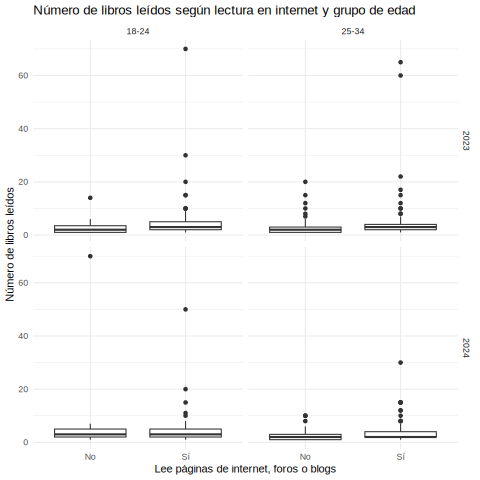

In [ ]:
%%R
# LECTURA EN INTERNET SEGUN EDAD Y USO DE INTERNET

internet_23 = M23limpia %>%
  filter(!is.na(p3_5)) %>%
  group_by(grupo_edad, p3_5) %>%
  summarise(n = n(), .groups = "drop") %>%
  group_by(grupo_edad) %>%
  mutate(Porcentaje = n / sum(n) * 100)

print(internet_23)

internet_24 = M24limpia %>%
  filter(!is.na(p3_5)) %>%
  group_by(grupo_edad, p3_5) %>%
  summarise(n = n(), .groups = "drop") %>%
  group_by(grupo_edad) %>%
  mutate(Porcentaje = n / sum(n) * 100)

print(internet_24)

### Sección 7: ¿Los que leen en internet leen más libros?

Cruzamos los datos para ver si las personas que leen cosas en internet también son las que leen más libros físicos o digitales.

# A tibble: 23 × 6
# Groups:   anio, grupo_edad, internet [8]
   anio  grupo_edad internet formato_libro     n Porcentaje
   <chr> <chr>      <chr>    <chr>         <int>      <dbl>
 1 2023  18-24      No       Solo digital      1       4.35
 2 2023  18-24      No       Solo impreso     22      95.7 
 3 2023  18-24      Sí       Ambos             9      10.5 
 4 2023  18-24      Sí       Solo digital     26      30.2 
 5 2023  18-24      Sí       Solo impreso     51      59.3 
 6 2023  25-34      No       Ambos             4       6.15
 7 2023  25-34      No       Solo digital      7      10.8 
 8 2023  25-34      No       Solo impreso     54      83.1 
 9 2023  25-34      Sí       Ambos            12      10.7 
10 2023  25-34      Sí       Solo digital     37      33.0 
# ℹ 13 more rows
# ℹ Use `print(n = ...)` to see more rows


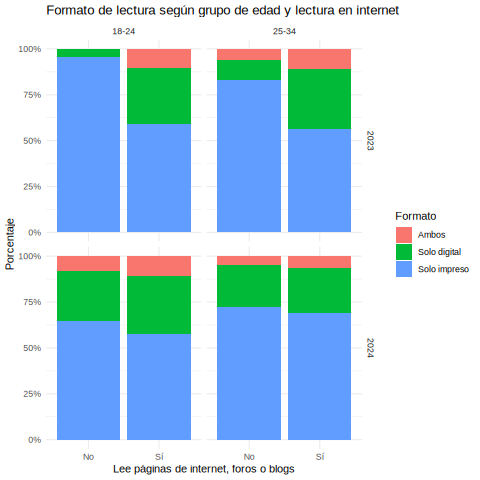

In [ ]:
%%R
# LECTURA DE LIBROS SEGUN INTERNET

libros_internet_23 = M23limpia %>%
  filter(!is.na(p3_5), !is.na(p3_1)) %>%
  group_by(grupo_edad, p3_5) %>%
  summarise(
    Total = n(),
    Leyeron_libros = sum(p3_1 == 1),
    Porcentaje = Leyeron_libros / Total * 100,
    .groups = "drop"
  )

print(libros_internet_23)

libros_internet_24 = M24limpia %>%
  filter(!is.na(p3_5), !is.na(p3_1)) %>%
  group_by(grupo_edad, p3_5) %>%
  summarise(
    Total = n(),
    Leyeron_libros = sum(p3_1 == 1),
    Porcentaje = Leyeron_libros / Total * 100,
    .groups = "drop"
  )

print(libros_internet_24)

### Sección 8: Gráfica de cajas de libros leídos

Hacemos una gráfica de cajas (boxplot) para comparar de forma clara la cantidad de libros leídos según el uso de internet en cada año.

In [ ]:
%%R
# LIBROS SEGUN INTERNET Y BOXPLOT

libros_grupo_23 = M23limpia %>%
  filter(!is.na(p4), !is.na(p3_5)) %>%
  group_by(grupo_edad, p3_5) %>%
  summarise(
    n = n(),
    Mediana = median(p4),
    Q1 = quantile(p4, 0.25),
    Q3 = quantile(p4, 0.75),
    RIC = IQR(p4),
    .groups = "drop"
  )

print(libros_grupo_23)

libros_grupo_24 = M24limpia %>%
  filter(!is.na(p4), !is.na(p3_5)) %>%
  group_by(grupo_edad, p3_5) %>%
  summarise(
    n = n(),
    Mediana = median(p4),
    Q1 = quantile(p4, 0.25),
    Q3 = quantile(p4, 0.75),
    RIC = IQR(p4),
    .groups = "drop"
  )

print(libros_grupo_24)

Mtotal_graf = Mtotal %>%
  filter(!is.na(p4), !is.na(p3_5)) %>%
  mutate(internet = ifelse(p3_5 == 1, "Sí", "No"))

ggplot(Mtotal_graf, aes(x = internet, y = p4)) +
  geom_boxplot() +
  facet_grid(anio ~ grupo_edad) +
  labs(
    title = "Número de libros leídos según lectura en internet y grupo de edad",
    x = "Lee páginas de internet, foros o blogs",
    y = "Número de libros leídos"
  ) +
  theme_minimal()

                    Indicador X2023 X2024
1            Lee internet (%) 56.75 52.17
2             Leyó libros (%) 49.48 51.99
3           Mediana de libros  2.00  2.00
4 Formato digital o ambos (%) 33.57 33.67


### Sección 9: ¿Papel o digital?

Revisamos qué prefiere la gente (libro físico, digital o ambos) dependiendo de si usan internet para leer o no.

In [ ]:
%%R
# FORMATO DE LECTURA Y GRAFICA

formato_total = Mtotal %>%
  filter(!is.na(p8_1), !is.na(p8_2), !is.na(p3_5)) %>%
  mutate(internet = ifelse(p3_5 == 1, "Sí", "No"))

tabla_formato = formato_total %>%
  group_by(anio, grupo_edad, internet, formato_libro) %>%
  summarise(n = n(), .groups = "drop") %>%
  group_by(anio, grupo_edad, internet) %>%
  mutate(Porcentaje = n / sum(n) * 100)

print(tabla_formato)

ggplot(tabla_formato, aes(x = internet, y = Porcentaje, fill = formato_libro)) +
  geom_col(position = "fill") +
  facet_grid(anio ~ grupo_edad) +
  scale_y_continuous(labels = scales::percent_format()) +
  labs(
    title = "Formato de lectura según grupo de edad y lectura en internet",
    x = "Lee páginas de internet, foros o blogs",
    y = "Porcentaje",
    fill = "Formato"
  ) +
  theme_minimal()

---- 2023: p3_1 vs NA en p4 ----
           p4_es_NA
Leyo_libros FALSE TRUE
       1      286    0
       2        0  292
       <NA>     0    1

---- 2024: p3_1 vs NA en p4 ----
           p4_es_NA
Leyo_libros FALSE TRUE
       1      300    0
       2        0  277
       <NA>     0    3

---- 2023: p3_1 vs NA en p7 ----
           p7_es_NA
Leyo_libros FALSE TRUE
       1      286    0
       2        0  292
       <NA>     0    1

---- 2024: p3_1 vs NA en p7 ----
           p7_es_NA
Leyo_libros FALSE TRUE
       1      300    0
       2        0  277
       <NA>     0    3

---- 2023: p3_1 vs NA en p8_1 ----
           p8_1_es_NA
Leyo_libros FALSE TRUE
       1      286    0
       2        0  292
       <NA>     0    1

---- 2024: p3_1 vs NA en p8_1 ----
           p8_1_es_NA
Leyo_libros FALSE TRUE
       1      300    0
       2        0  277
       <NA>     0    3

---- 2023: p3_1 vs NA en p8_2 ----
           p8_2_es_NA
Leyo_libros FALSE TRUE
       1      286    0
       2     

### Sección 10: Comparación rápida 2023 vs 2024

Hacemos una tabla resumen chiquita para ver qué tanto cambiaron las cosas de un año al otro.

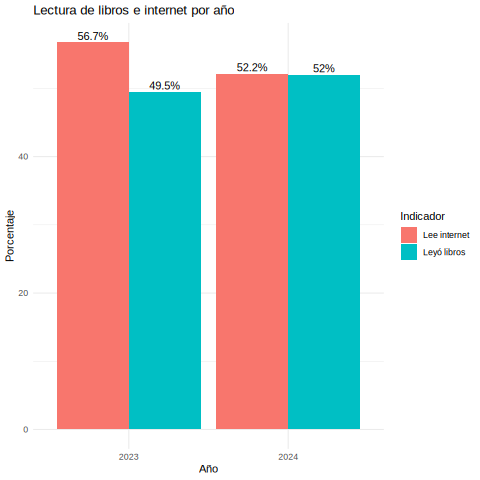

In [ ]:
%%R
# TABLA RESUMEN GENERAL 2023 vs 2024

internet_23_glob = mean(M23limpia$p3_5 == 1, na.rm = TRUE) * 100
internet_24_glob = mean(M24limpia$p3_5 == 1, na.rm = TRUE) * 100

libros_23_glob = mean(M23limpia$p3_1 == 1, na.rm = TRUE) * 100
libros_24_glob = mean(M24limpia$p3_1 == 1, na.rm = TRUE) * 100

mediana_libros_23 = median(M23limpia$p4, na.rm = TRUE)
mediana_libros_24 = median(M24limpia$p4, na.rm = TRUE)

digital_ambos_23 = sum(M23limpia$formato_libro %in% c("Solo digital", "Ambos"), na.rm = TRUE) /
  sum(!is.na(M23limpia$formato_libro)) * 100

digital_ambos_24 = sum(M24limpia$formato_libro %in% c("Solo digital", "Ambos"), na.rm = TRUE) /
  sum(!is.na(M24limpia$formato_libro)) * 100

Tabla_resumen = data.frame(
  Indicador = c(
    "Lee internet (%)",
    "Leyó libros (%)",
    "Mediana de libros",
    "Formato digital o ambos (%)"
  ),
  `2023` = c(internet_23_glob, libros_23_glob, mediana_libros_23, digital_ambos_23),
  `2024` = c(internet_24_glob, libros_24_glob, mediana_libros_24, digital_ambos_24)
)

Tabla_resumen$X2023 = round(Tabla_resumen$X2023, 2)
Tabla_resumen$X2024 = round(Tabla_resumen$X2024, 2)

print(Tabla_resumen)

### Sección 11: Anexo B - Revisar que las respuestas tengan sentido

Checamos que los filtros de la encuesta se hayan respetado; por ejemplo, que los que dijeron que no leen no tengan anotados libros leídos por error.

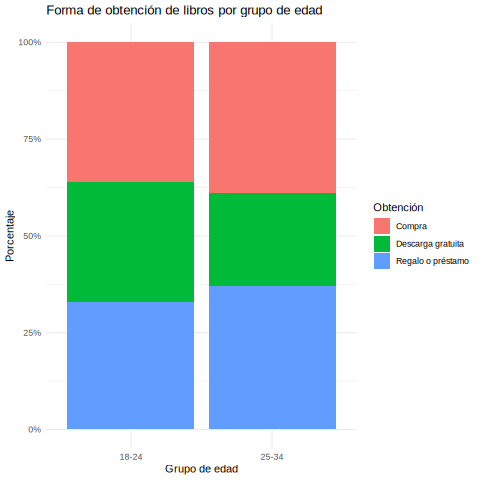

In [ ]:
%%R
# ANEXO B - VERIFICACION DE SALTOS DEL CUESTIONARIO

cat("---- 2023: p3_1 vs NA en p4 ----\n")
print(table(Leyo_libros = M23limpia$p3_1, p4_es_NA = is.na(M23limpia$p4), useNA = "ifany"))

cat("\n---- 2024: p3_1 vs NA en p4 ----\n")
print(table(Leyo_libros = M24limpia$p3_1, p4_es_NA = is.na(M24limpia$p4), useNA = "ifany"))

cat("\n---- 2023: p3_1 vs NA en p7 ----\n")
print(table(Leyo_libros = M23limpia$p3_1, p7_es_NA = is.na(M23limpia$p7), useNA = "ifany"))

cat("\n---- 2024: p3_1 vs NA en p7 ----\n")
print(table(Leyo_libros = M24limpia$p3_1, p7_es_NA = is.na(M24limpia$p7), useNA = "ifany"))

cat("\n---- 2023: p3_1 vs NA en p8_1 ----\n")
print(table(Leyo_libros = M23limpia$p3_1, p8_1_es_NA = is.na(M23limpia$p8_1), useNA = "ifany"))

cat("\n---- 2024: p3_1 vs NA en p8_1 ----\n")
print(table(Leyo_libros = M24limpia$p3_1, p8_1_es_NA = is.na(M24limpia$p8_1), useNA = "ifany"))

cat("\n---- 2023: p3_1 vs NA en p8_2 ----\n")
print(table(Leyo_libros = M23limpia$p3_1, p8_2_es_NA = is.na(M23limpia$p8_2), useNA = "ifany"))

cat("\n---- 2024: p3_1 vs NA en p8_2 ----\n")
print(table(Leyo_libros = M24limpia$p3_1, p8_2_es_NA = is.na(M24limpia$p8_2), useNA = "ifany"))

### Sección 12: Anexo C - Gráficas de cómo consiguen los libros

Hacemos unas gráficas extras para ver de dónde saca la gente sus libros (si los compran, se los prestan o los bajan gratis).

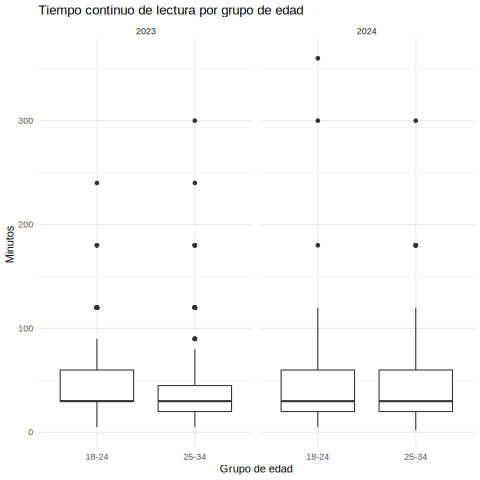

In [ ]:
%%R
# ANEXO C - GRAFICAS COMPLEMENTARIAS

tabla_general = data.frame(
  anio = c("2023","2023","2024","2024"),
  indicador = c("Leyó libros", "Lee internet", "Leyó libros", "Lee internet"),
  porcentaje = c(
    mean(M23limpia$p3_1 == 1, na.rm = TRUE) * 100,
    mean(M23limpia$p3_5 == 1, na.rm = TRUE) * 100,
    mean(M24limpia$p3_1 == 1, na.rm = TRUE) * 100,
    mean(M24limpia$p3_5 == 1, na.rm = TRUE) * 100
  )
)

# C1. Lectura por año
ggplot(tabla_general, aes(x = anio, y = porcentaje, fill = indicador)) +
  geom_col(position = "dodge") +
  geom_text(aes(label = paste0(round(porcentaje,1), "%")), position = position_dodge(width = 0.9), vjust = -0.3) +
  labs(title = "Lectura de libros e internet por año", x = "Año", y = "Porcentaje", fill = "Indicador") +
  theme_minimal()

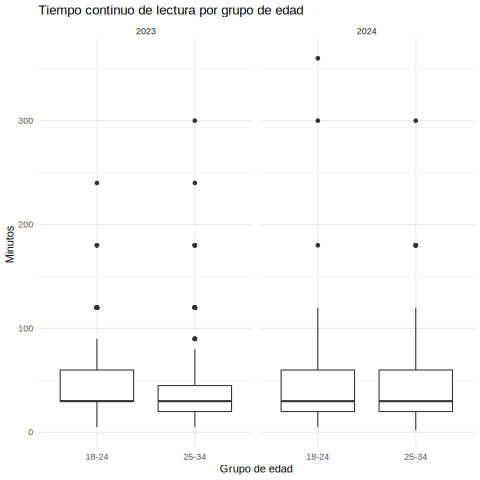

In [ ]:
%%R
# C2. Obtención de libros según grupo de edad

tabla_p7 = Mtotal %>%
  filter(!is.na(p7)) %>%
  mutate(
    obtencion = case_when(
      p7 == 1 ~ "Descarga gratuita",
      p7 == 2 ~ "Regalo o préstamo",
      p7 == 3 ~ "Compra"
    )
  ) %>%
  group_by(grupo_edad, obtencion) %>%
  summarise(n = n(), .groups = "drop") %>%
  group_by(grupo_edad) %>%
  mutate(Porcentaje = n / sum(n) * 100)

ggplot(tabla_p7, aes(x = grupo_edad, y = Porcentaje, fill = obtencion)) +
  geom_col(position = "fill") +
  scale_y_continuous(labels = scales::percent_format()) +
  labs(title = "Forma de obtención de libros por grupo de edad", x = "Grupo de edad", y = "Porcentaje", fill = "Obtención") +
  theme_minimal()

### Sección 13: Anexo D - Tiempo de lectura y estudios

Para terminar, vemos cuánto tiempo seguido lee la gente y si el nivel de escuela que terminaron influye en que lean más o menos.

In [ ]:
%%R
# C3. Tiempo de lectura y ANEXO D - Lectura según escolaridad

# Boxplot del tiempo continuo de lectura
ggplot(Mtotal %>% filter(!is.na(p26)), aes(x = grupo_edad, y = p26)) +
  geom_boxplot() +
  facet_wrap(~anio) +
  labs(title = "Tiempo continuo de lectura por grupo de edad", x = "Grupo de edad", y = "Minutos") +
  theme_minimal()

# Tabla de escolaridad
tabla_escolaridad = Mtotal %>%
  filter(!is.na(nivel)) %>%
  group_by(grupo_edad, nivel) %>%
  summarise(
    n = n(),
    Porcentaje_lee_internet = mean(p3_5 == 1, na.rm = TRUE) * 100,
    Porcentaje_leyo_libros = mean(p3_1 == 1, na.rm = TRUE) * 100,
    .groups = "drop"
  )

tabla_escolaridad$Porcentaje_lee_internet = round(tabla_escolaridad$Porcentaje_lee_internet, 1)
tabla_escolaridad$Porcentaje_leyo_libros = round(tabla_escolaridad$Porcentaje_leyo_libros, 1)

print(tabla_escolaridad)

# A tibble: 14 × 5
   grupo_edad nivel     n Porcentaje_lee_internet Porcentaje_leyo_libros
   <chr>      <int> <int>                   <dbl>                  <dbl>
 1 18-24          0     1                   NaN                    NaN  
 2 18-24          2    13                    53.8                   15.4
 3 18-24          3    59                    33.9                   25.4
 4 18-24          4   163                    58.3                   55.8
 5 18-24          6     8                    62.5                   75  
 6 18-24          7   145                    73.1                   73.1
 7 18-24          8     2                    50                     50  
 8 25-34          0     1                     0                      0  
 9 25-34          2    27                    15.4                   26.9
10 25-34          3   159                    36.3                   30.6
11 25-34          4   235                    49.4                   39.1
12 25-34          6    21       